# Preliminary CKGE Results Exploration

Exploring `ckge_prelimary_results.csv`: the preliminary sweep over UMLS and KINSHIP, all 3 update scenarios (existing_entities, new_entities, mixed), 5 snapshots, multiple seeds, and a full Chebyshev **beta × cheb_K** grid sweep (beta in {0.05, 0.5, 1, 2, 5, 10}, cheb_K in {1, 2, 3, 4, 5}), comparing `retrain_from_scratch` (oracle), `finetune`, `uniform`, and `chebyshev`.

Contents:
1. Load & sanity-check the data
2. Summary tables (mean ± std across seeds) per dataset/scenario/method/step
3. MRR evolution across snapshots (line plots, per scenario, with error bands)
4. Method comparison bar charts (final snapshot)
5. Gap-to-oracle analysis (how much of the retrain-from-scratch performance each method recovers)
6. Runtime comparison (continual methods vs. oracle)
7. Beta sensitivity analysis for Chebyshev
8. Chebyshev order (cheb_K) sensitivity analysis
9. Training loss decay curves


In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

CSV_PATH = "ckge_prelimary_results.csv"

df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()


(2988, 20)


,dataset,scenario,seed,beta,cheb_K,step,method,num_cumulative_triples,num_added_triples,num_new_entities,num_new_relations,test_MRR,test_H@1,test_H@3,test_H@10,training_time_seconds,first_epoch_loss,last_epoch_loss,min_epoch_loss,num_epochs
0,UMLS,existing_entities,0,NaN,NaN,0,base_model,2608,2608,NaN,NaN,0.400538,0.276097,0.447050,0.657337,0.900591,NaN,NaN,NaN,NaN
1,UMLS,existing_entities,0,NaN,NaN,1,finetune,3130,522,0.0,1.0,0.381732,0.242814,0.433434,0.657337,0.085651,2.460763,0.478953,0.474528,10.0
2,UMLS,existing_entities,0,NaN,NaN,1,uniform,3130,522,0.0,1.0,0.373826,0.236762,0.427383,0.658094,0.058244,4.050508,0.418130,0.418130,10.0
3,UMLS,existing_entities,0,NaN,NaN,1,retrain_from_scratch,3130,522,0.0,1.0,0.427844,0.305598,0.466717,0.689107,0.299481,1.763572,0.042214,0.042214,50.0
4,UMLS,existing_entities,0,NaN,NaN,2,finetune,3652,522,0.0,0.0,0.438099,0.295008,0.506808,0.741301,0.085428,1.834515,0.674284,0.284979,10.0


## 1. Sanity checks

`beta` is only meaningful for the `chebyshev` method (NaN for everything else). `base_model`
rows only exist at step 0 (the initial T0 training, before any continual updates) and have no
`beta`/method comparison -- they represent the starting point every method branches from.


In [55]:
print("datasets:", sorted(df["dataset"].unique()))
print("scenarios:", sorted(df["scenario"].unique()))
print("methods:", sorted(df["method"].unique()))
print("seeds:", sorted(df["seed"].unique()))
print("steps:", sorted(df["step"].unique()))
print("betas (chebyshev only):", sorted(df.loc[df["method"] == "chebyshev", "beta"].unique()))
print("cheb_Ks (chebyshev only):", sorted(df.loc[df["method"] == "chebyshev", "cheb_K"].unique()))

# Expected row counts per (dataset, scenario): 1 base_model (T0) + 5 steps x {finetune, uniform, retrain}
# + 5 steps x (6 betas x 5 cheb_Ks) chebyshev grid cells
counts = df.groupby(["dataset", "scenario"]).size()

counts

datasets: ['KINSHIP', 'UMLS']
scenarios: ['existing_entities', 'mixed', 'new_entities']
methods: ['base_model', 'chebyshev', 'finetune', 'retrain_from_scratch', 'uniform']
seeds: [0, 1, 2]
steps: [0, 1, 2, 3, 4, 5]
betas (chebyshev only): [0.05, 0.1, 0.5, 1.0, 2.0]
cheb_Ks (chebyshev only): [1.0, 2.0, 3.0, 4.0, 5.0]


dataset  scenario         
KINSHIP  existing_entities    498
         mixed                498
         new_entities         498
UMLS     existing_entities    498
         mixed                498
         new_entities         498
dtype: int64

## 2. Build a unified comparison frame

For plotting across methods on equal footing we need one row per (dataset, scenario, seed, step,
method). For `chebyshev` there are multiple (beta, cheb_K) grid cells; we keep the full grid for
the beta- and cheb_K-sensitivity sections, but for the main method-comparison plots we pick, per
(dataset, scenario), the single best (beta, cheb_K) pair (highest mean final-step MRR across
seeds) and treat that as "chebyshev (best config)".


In [56]:
non_cheb = df[df["method"] != "chebyshev"].copy()
cheb = df[df["method"] == "chebyshev"].copy()

max_step = df["step"].max()

# Pick the best (beta, cheb_K) pair per (dataset, scenario) using mean MRR at the final step,
# averaged over seeds.
final_cheb = cheb[cheb["step"] == max_step]
config_scores = (
    final_cheb.groupby(["dataset", "scenario", "beta", "cheb_K"])["test_MRR"]
    .mean()
    .reset_index()
)
best_configs = (
    config_scores.sort_values("test_MRR", ascending=False)
    .groupby(["dataset", "scenario"])
    .first()
    .reset_index()[["dataset", "scenario", "beta", "cheb_K"]]
    .rename(columns={"beta": "best_beta", "cheb_K": "best_cheb_K"})
)
print("Best (beta, cheb_K) per (dataset, scenario) by final-step mean MRR:")
best_configs


Best (beta, cheb_K) per (dataset, scenario) by final-step mean MRR:


,dataset,scenario,best_beta,best_cheb_K
0,KINSHIP,existing_entities,0.10,1.0
1,KINSHIP,mixed,0.50,2.0
2,KINSHIP,new_entities,0.50,1.0
3,UMLS,existing_entities,0.10,1.0
4,UMLS,mixed,0.10,2.0
5,UMLS,new_entities,0.05,5.0


In [57]:
# Merge in the best (beta, cheb_K) pair per (dataset, scenario), then keep only those chebyshev
# rows, relabel method so it stands alone in comparisons, and concat with the non-chebyshev methods.
cheb_with_best = cheb.merge(best_configs, on=["dataset", "scenario"])
cheb_best = cheb_with_best[
    (cheb_with_best["beta"] == cheb_with_best["best_beta"])
    & (cheb_with_best["cheb_K"] == cheb_with_best["best_cheb_K"])
].copy()
cheb_best["method"] = "chebyshev (best config)"
cheb_best = cheb_best.drop(columns=["best_beta", "best_cheb_K"])

comparison_df = pd.concat([non_cheb, cheb_best], ignore_index=True, sort=False)
comparison_df["method"] = pd.Categorical(
    comparison_df["method"],
    categories=["base_model", "retrain_from_scratch", "finetune", "uniform", "chebyshev (best config)"],
    ordered=True,
)

# NOTE: not every (dataset, scenario) necessarily reaches the same global max step -- e.g. a
# materialized dataset snapshot folder reused from an earlier run with a different --num_steps
# can leave one combo with fewer steps than the rest. Compute the "final snapshot" per
# (dataset, scenario) rather than assuming a single global max_step, so partial-coverage combos
# still show up in every downstream table/plot instead of silently disappearing.
comparison_df["final_step"] = comparison_df.groupby(["dataset", "scenario"])["step"].transform("max")

step_coverage = comparison_df.groupby(["dataset", "scenario"])["step"].max().rename("final_step_reached")
print("Final step actually reached per (dataset, scenario) (should all equal the global max if fully covered):")
print(step_coverage)
print()
print(comparison_df.shape)
comparison_df.head()
step_coverage = comparison_df.groupby(["dataset", "scenario"])["step"].max().rename("final_step_reached")

Final step actually reached per (dataset, scenario) (should all equal the global max if fully covered):
dataset  scenario         
KINSHIP  existing_entities    5
         mixed                5
         new_entities         5
UMLS     existing_entities    5
         mixed                5
         new_entities         5
Name: final_step_reached, dtype: int64

(828, 21)


## 3. Summary tables (mean ± std across seeds)

Final-snapshot MRR per (dataset, scenario, method), aggregated across the 5 seeds.


In [58]:
def mean_std_fmt(s):
    return f"{s.mean():.4f} ± {s.std():.4f}"

final_step_df = comparison_df[(comparison_df["step"] == comparison_df["final_step"]) & (comparison_df["method"] != "base_model")]

summary_table = (
    final_step_df
    .groupby(["dataset", "scenario", "method"], observed=True)["test_MRR"]
    .agg(mean_std_fmt)
    .unstack("method")
)
print(f"Final-snapshot test MRR (per (dataset, scenario) actual last step, see step_coverage above), mean ± std over {df['seed'].nunique()} seeds:")
summary_table


Final-snapshot test MRR (per (dataset, scenario) actual last step, see step_coverage above), mean ± std over 3 seeds:


method                    retrain_from_scratch         finetune          uniform chebyshev (best config)
dataset scenario                                                                                        
KINSHIP existing_entities      0.4792 ± 0.0124  0.4019 ± 0.0185  0.4062 ± 0.0139         0.4094 ± 0.0119
        mixed                  0.4815 ± 0.0172  0.2456 ± 0.0010  0.3097 ± 0.0209         0.3022 ± 0.0312
        new_entities           0.4862 ± 0.0091  0.2371 ± 0.0046  0.3110 ± 0.0220         0.2997 ± 0.0053
UMLS    existing_entities      0.5010 ± 0.0128  0.4758 ± 0.0047  0.5119 ± 0.0091         0.5186 ± 0.0277
        mixed                  0.5009 ± 0.0091  0.2725 ± 0.0469  0.3373 ± 0.0483         0.3698 ± 0.0293
        new_entities           0.4952 ± 0.0115  0.2488 ± 0.0420  0.3352 ± 0.0293         0.3676 ± 0.0378

In [59]:
# Full metric table (raw numeric mean/std columns, easier for further programmatic analysis)
full_summary = (
    final_step_df
    .groupby(["dataset", "scenario", "method"], observed=True)[["test_MRR", "test_H@1", "test_H@3", "test_H@10", "training_time_seconds"]]
    .agg(["mean", "std"])
    .round(3)
)
full_summary


test_MRR        test_H@1        test_H@3        test_H@10        training_time_seconds       
                                                      mean    std     mean    std     mean    std      mean    std                  mean    std
dataset scenario          method                                                                                                               
KINSHIP existing_entities retrain_from_scratch       0.479  0.012    0.320  0.010    0.544  0.017     0.850  0.017                 0.707  0.013
                          finetune                   0.402  0.019    0.237  0.026    0.462  0.014     0.788  0.005                 0.068  0.001
                          uniform                    0.406  0.014    0.235  0.019    0.465  0.023     0.808  0.009                 0.088  0.001
                          chebyshev (best config)    0.409  0.012    0.240  0.016    0.471  0.007     0.809  0.006                 0.098  0.001
        mixed             retrain_from_scratch       0.481  0.017    0.324  0.015    0.545  0.026     0.852  0.019                 1.162  0.810
                          finetune                   0.246  0.001    0.116  0.012    0.258  0.010     0.540  0.030                 0.113  0.004
                          uniform                    0.310  0.021    0.154  0.026    0.341  0.021     0.688  0.007                 0.156  0.009
                          chebyshev (best config)    0.302  0.031    0.147  0.033    0.330  0.034     0.685  0.032                 0.164  0.002
        new_entities      retrain_from_scratch       0.486  0.009    0.328  0.011    0.552  0.008     0.856  0.006                 0.715  0.044
                          finetune                   0.237  0.005    0.115  0.004    0.248  0.005     0.507  0.020                 0.109  0.000
                          uniform                    0.311  0.022    0.153  0.019    0.346  0.026     0.698  0.032                 0.161  0.018
                          chebyshev (best config)    0.300  0.005    0.143  0.010    0.336  0.003     0.687  0.012                 0.170  0.013
UMLS    existing_entities retrain_from_scratch       0.501  0.013    0.380  0.022    0.544  0.002     0.743  0.013                 0.993  0.012
                          finetune                   0.476  0.005    0.331  0.009    0.545  0.005     0.769  0.012                 0.073  0.026
                          uniform                    0.512  0.009    0.368  0.014    0.586  0.012     0.796  0.005                 0.061  0.002
                          chebyshev (best config)    0.519  0.028    0.382  0.035    0.586  0.025     0.797  0.019                 0.137  0.067
        mixed             retrain_from_scratch       0.501  0.009    0.391  0.010    0.540  0.007     0.721  0.009                 0.599  0.146
                          finetune                   0.273  0.047    0.161  0.036    0.302  0.057     0.484  0.059                 0.060  0.009
                          uniform                    0.337  0.048    0.206  0.045    0.383  0.050     0.605  0.072                 0.102  0.041
                          chebyshev (best config)    0.370  0.029    0.242  0.030    0.413  0.034     0.634  0.031                 0.093  0.002
        new_entities      retrain_from_scratch       0.495  0.012    0.382  0.016    0.536  0.011     0.733  0.009                 0.685  0.283
                          finetune                   0.249  0.042    0.140  0.029    0.267  0.052     0.475  0.088                 0.074  0.019
                          uniform                    0.335  0.029    0.197  0.021    0.383  0.036     0.619  0.049                 0.077  0.010
                          chebyshev (best config)    0.368  0.038    0.241  0.021    0.404  0.061     0.632  0.076                 0.085  0.011

## 4. MRR evolution across snapshots

One subplot per (dataset, scenario), lines = methods (mean over seeds), shaded band = ± 1 std.
`base_model` is plotted as a single point at step 0 shared by all methods (their common starting point).


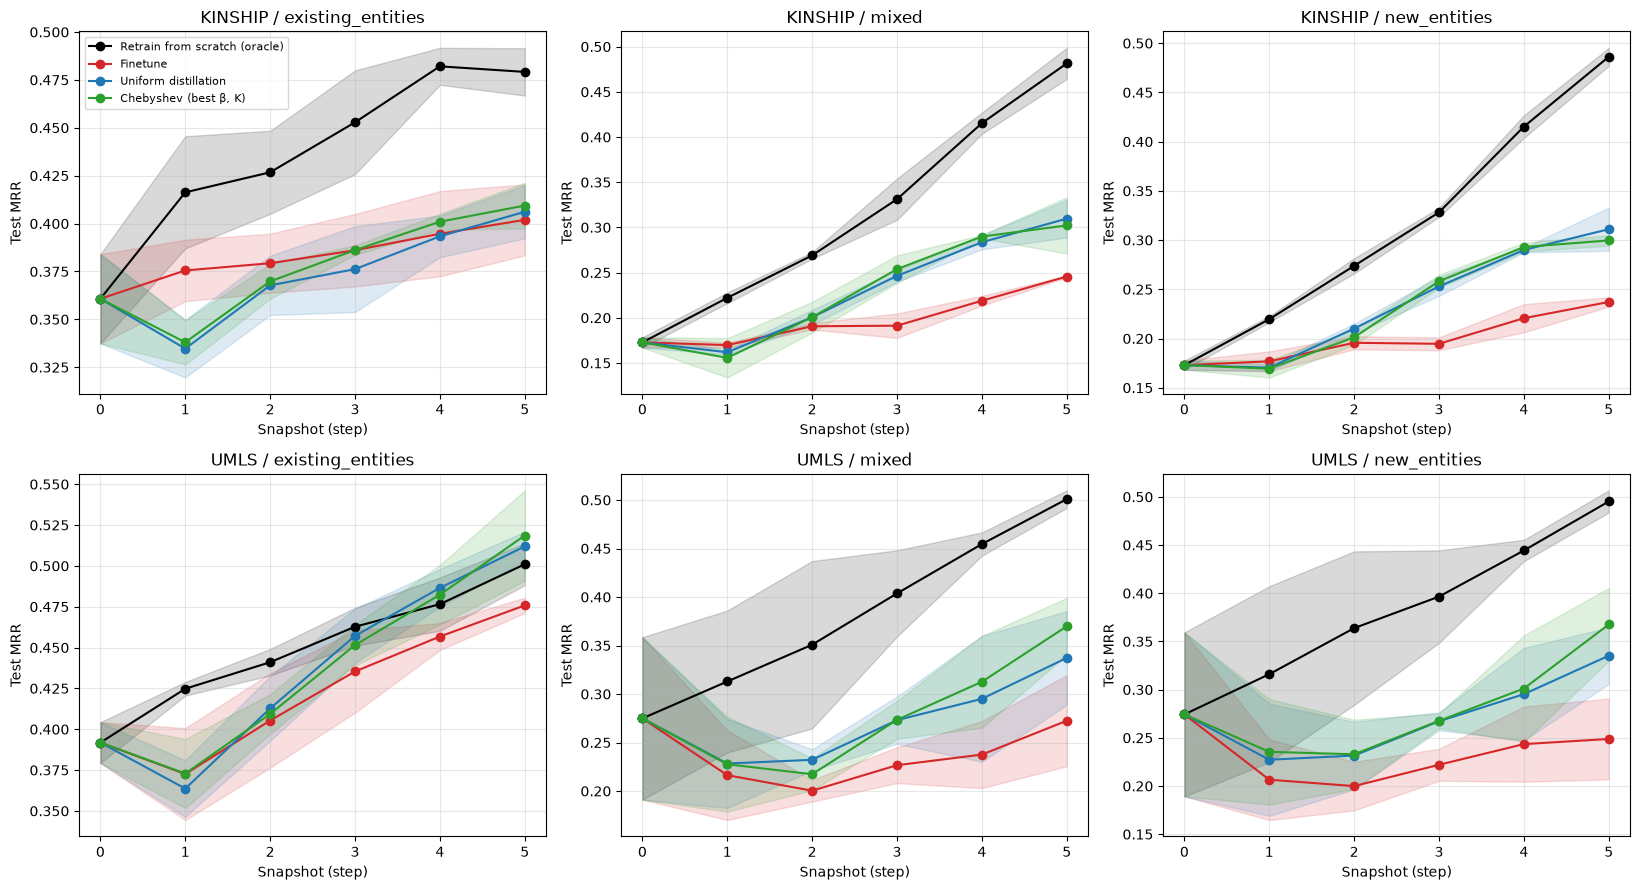

In [60]:
METHOD_COLORS = {
    "retrain_from_scratch": "black",
    "finetune": "tab:red",
    "uniform": "tab:blue",
    "chebyshev (best config)": "tab:green",
}
METHOD_LABELS = {
    "retrain_from_scratch": "Retrain from scratch (oracle)",
    "finetune": "Finetune",
    "uniform": "Uniform distillation",
    "chebyshev (best config)": "Chebyshev (best β, K)",
}

datasets = sorted(comparison_df["dataset"].unique())
scenarios = sorted(comparison_df["scenario"].unique())

fig, axes = plt.subplots(len(datasets), len(scenarios), figsize=(5.5 * len(scenarios), 4.5 * len(datasets)), squeeze=False)

base_model_df = comparison_df[comparison_df["method"] == "base_model"]

for i, dataset in enumerate(datasets):
    for j, scenario in enumerate(scenarios):
        ax = axes[i][j]
        sub = comparison_df[
            (comparison_df["dataset"] == dataset)
            & (comparison_df["scenario"] == scenario)
            & (comparison_df["method"] != "base_model")
        ]
        base = base_model_df[(base_model_df["dataset"] == dataset) & (base_model_df["scenario"] == scenario)]
        base_mean, base_std = base["test_MRR"].mean(), base["test_MRR"].std()

        for method in ["retrain_from_scratch", "finetune", "uniform", "chebyshev (best config)"]:
            m = sub[sub["method"] == method]
            if m.empty:
                continue
            stats = m.groupby("step")["test_MRR"].agg(["mean", "std"]).reset_index()
            steps = [0] + stats["step"].tolist()
            means = [base_mean] + stats["mean"].tolist()
            stds = [base_std] + stats["std"].fillna(0).tolist()
            means = np.array(means)
            stds = np.array(stds)
            ax.plot(steps, means, marker="o", label=METHOD_LABELS[method], color=METHOD_COLORS[method])
            ax.fill_between(steps, means - stds, means + stds, color=METHOD_COLORS[method], alpha=0.15)

        ax.set_title(f"{dataset} / {scenario}")
        ax.set_xlabel("Snapshot (step)")
        ax.set_ylabel("Test MRR")
        ax.grid(alpha=0.3)
        if i == 0 and j == 0:
            ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## 5. Method comparison bar charts (final snapshot)

Bar height = mean final-step MRR across seeds, error bars = ± 1 std, grouped by scenario, one
subplot per dataset.


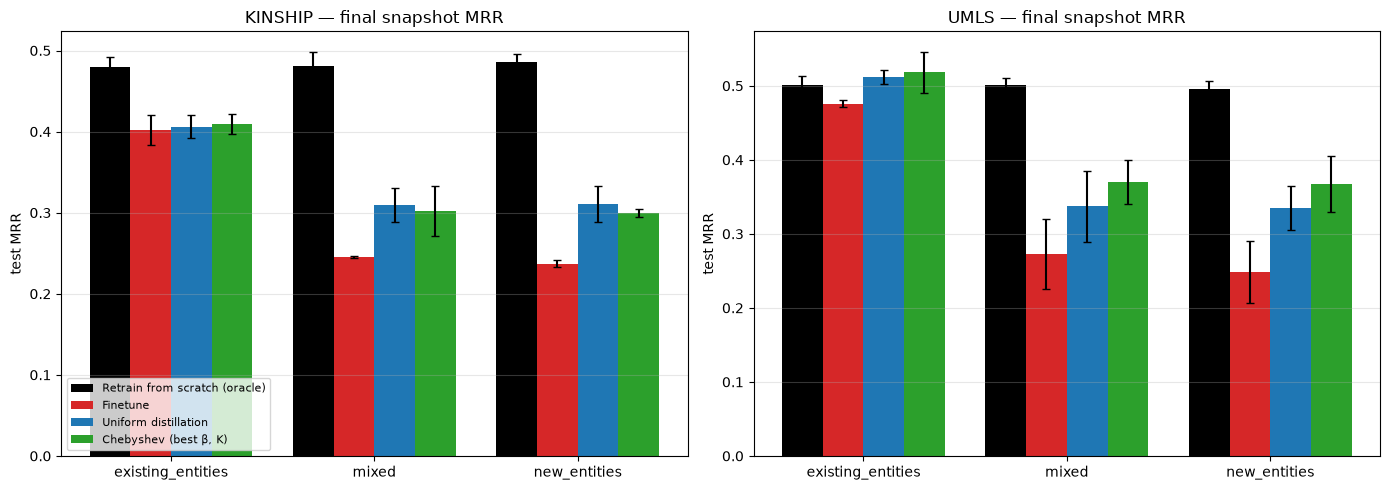

In [61]:
bar_methods = ["retrain_from_scratch", "finetune", "uniform", "chebyshev (best config)"]

fig, axes = plt.subplots(1, len(datasets), figsize=(7 * len(datasets), 5), squeeze=False)
axes = axes[0]

width = 0.8 / len(bar_methods)

for col, dataset in enumerate(datasets):
    ax = axes[col]
    sub = final_step_df[final_step_df["dataset"] == dataset]
    x = np.arange(len(scenarios))

    for i, method in enumerate(bar_methods):
        means, stds = [], []
        for scenario in scenarios:
            vals = sub[(sub["scenario"] == scenario) & (sub["method"] == method)]["test_MRR"]
            means.append(vals.mean() if len(vals) else np.nan)
            stds.append(vals.std() if len(vals) else np.nan)
        ax.bar(
            x + (i - (len(bar_methods) - 1) / 2) * width,
            means,
            width=width,
            yerr=stds,
            capsize=3,
            label=METHOD_LABELS.get(method, method),
            color=METHOD_COLORS.get(method, None),
        )

    ax.set_xticks(x)
    ax.set_xticklabels(scenarios)
    ax.set_title(f"{dataset} — final snapshot MRR")
    ax.set_ylabel("test MRR")
    ax.grid(True, axis="y", alpha=0.3)
    if col == 0:
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## 6. Gap-to-oracle analysis

For each (dataset, scenario, seed, step) we define the "gap closed" by a continual method as:

$$
\text{gap\_closed} = \frac{\text{MRR}_{\text{method}} - \text{MRR}_{\text{base\_model}}}{\text{MRR}_{\text{oracle}} - \text{MRR}_{\text{base\_model}}}
$$

where `oracle` = `retrain_from_scratch` at the same step, and `base_model` is the shared step-0
starting point. A value of 1.0 means the method fully recovers the oracle's improvement over the
base model; 0.0 means no improvement at all. This metric is seed-matched (computed per seed, then
averaged) so it also captures variance correctly.


In [46]:
base_per_seed = base_model_df_full = df[df["method"] == "base_model"][
    ["dataset", "scenario", "seed", "test_MRR"]
].rename(columns={"test_MRR": "base_MRR"})

oracle_per_seed = comparison_df[comparison_df["method"] == "retrain_from_scratch"][
    ["dataset", "scenario", "seed", "step", "test_MRR"]
].rename(columns={"test_MRR": "oracle_MRR"})

gap_methods = ["finetune", "uniform", "chebyshev (best config)"]
gap_df = comparison_df[comparison_df["method"].isin(gap_methods)].copy()
gap_df = gap_df.merge(base_per_seed, on=["dataset", "scenario", "seed"], how="left")
gap_df = gap_df.merge(oracle_per_seed, on=["dataset", "scenario", "seed", "step"], how="left")

denom = gap_df["oracle_MRR"] - gap_df["base_MRR"]
gap_df["gap_closed"] = np.where(
    denom.abs() > 1e-9, (gap_df["test_MRR"] - gap_df["base_MRR"]) / denom, np.nan
)

gap_summary = (
    gap_df[gap_df["step"] == gap_df["final_step"]]
    .groupby(["dataset", "scenario", "method"])["gap_closed"]
    .agg(["mean", "std"])
    .round(3)
)
print("Fraction of oracle's MRR improvement recovered at each combo's final snapshot (mean ± std over seeds):")
gap_summary


Fraction of oracle's MRR improvement recovered at each combo's final snapshot (mean ± std over seeds):


mean    std
dataset scenario          method                               
KINSHIP existing_entities finetune                 0.310  0.160
                          uniform                  0.313  0.113
        mixed             finetune                 0.183  0.034
                          uniform                  0.394  0.033
                          chebyshev (best config)  0.429  0.028
        new_entities      finetune                 0.175  0.033
                          uniform                  0.378  0.027
                          chebyshev (best config)  0.405  0.043
UMLS    existing_entities finetune                 0.892  0.193
                          uniform                  0.901  0.148
                          chebyshev (best config)  0.986  0.189
        mixed             finetune                 0.279  0.074
                          uniform                  0.507  0.072
                          chebyshev (best config)  0.669  0.058
        new_entities      finetune                 0.388  0.103
                          uniform                  0.555  0.045
                          chebyshev (best config)  0.634  0.055

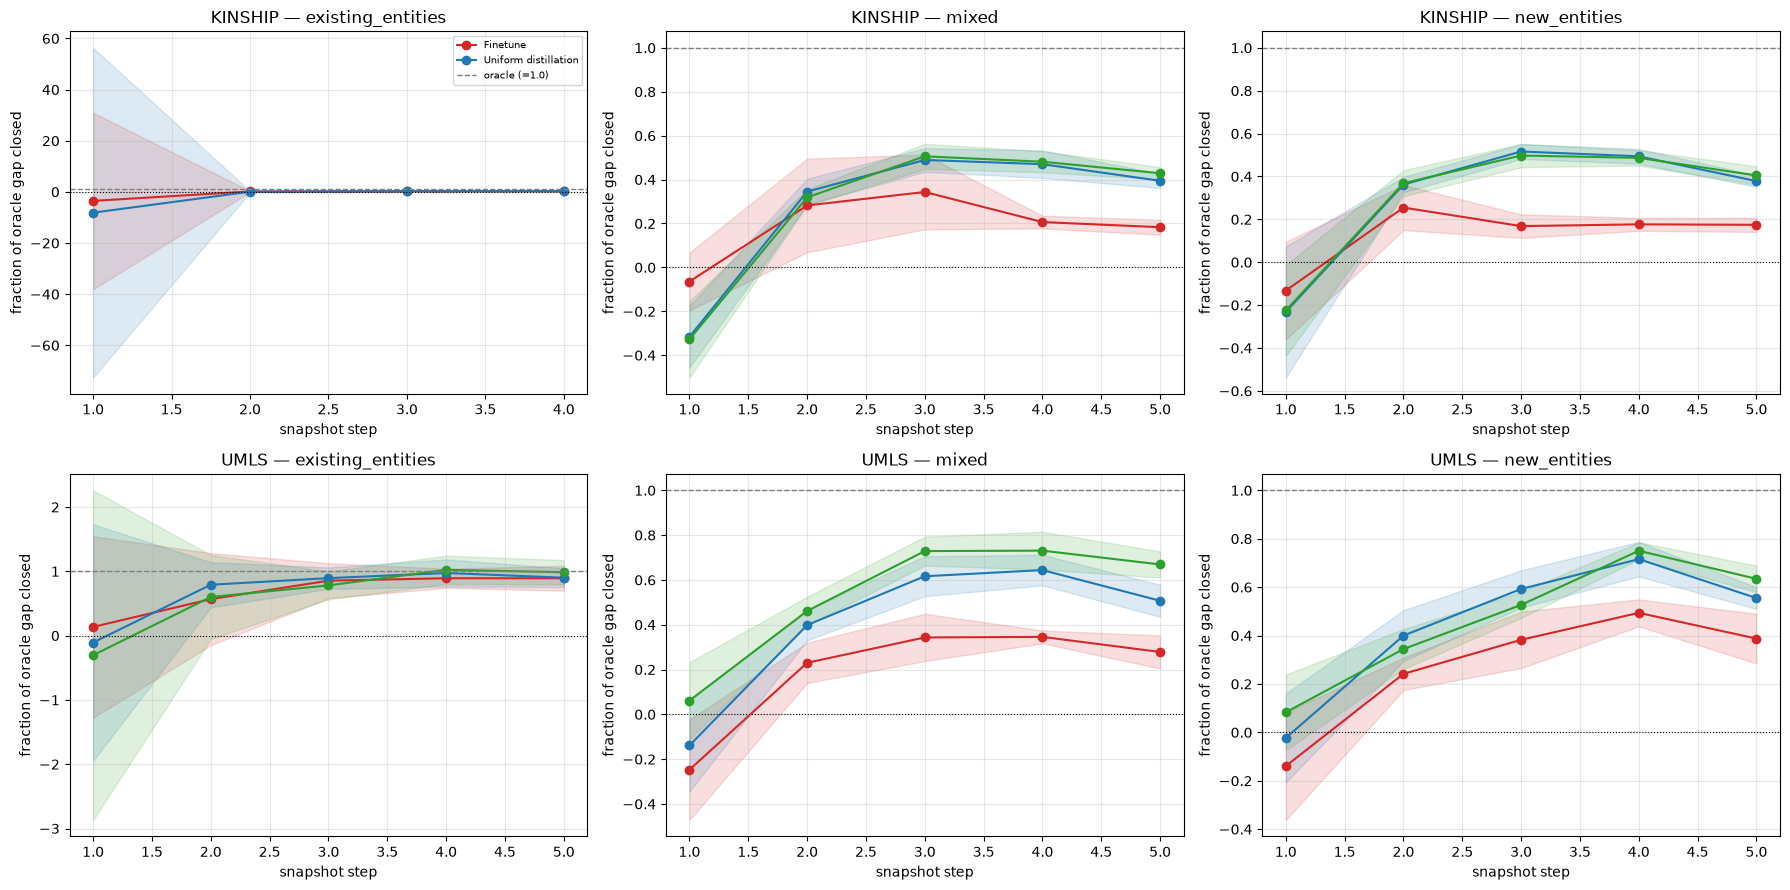

In [47]:
fig, axes = plt.subplots(len(datasets), len(scenarios), figsize=(6 * len(scenarios), 4.5 * len(datasets)), squeeze=False)

for row, dataset in enumerate(datasets):
    for col, scenario in enumerate(scenarios):
        ax = axes[row][col]
        sub = gap_df[(gap_df["dataset"] == dataset) & (gap_df["scenario"] == scenario)]
        for method in gap_methods:
            msub = sub[sub["method"] == method].groupby("step")["gap_closed"].agg(["mean", "std"])
            if msub.empty:
                continue
            ax.plot(msub.index, msub["mean"], marker="o", label=METHOD_LABELS.get(method, method),
                     color=METHOD_COLORS.get(method, None))
            ax.fill_between(msub.index, msub["mean"] - msub["std"], msub["mean"] + msub["std"],
                             alpha=0.15, color=METHOD_COLORS.get(method, None))
        ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="oracle (=1.0)")
        ax.axhline(0.0, color="black", linestyle=":", linewidth=0.8)
        ax.set_title(f"{dataset} — {scenario}")
        ax.set_xlabel("snapshot step")
        ax.set_ylabel("fraction of oracle gap closed")
        ax.grid(True, alpha=0.3)
        if row == 0 and col == 0:
            ax.legend(fontsize=7)

plt.tight_layout()
plt.show()


## 7. Training time comparison

Continual methods (finetune/uniform/chebyshev) are expected to be substantially cheaper per
snapshot than retraining from scratch (oracle), since they only train on a small incremental
sample instead of the full cumulative graph. Shown per dataset, aggregated over all scenarios,
seeds and steps (log-scale y-axis since the oracle cost grows with cumulative graph size).


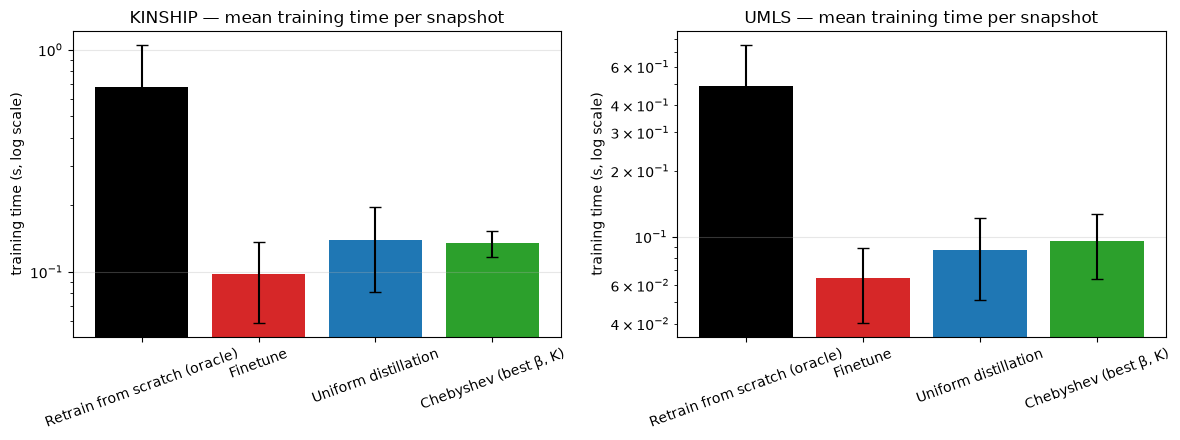

mean   std
dataset method                             
KINSHIP retrain_from_scratch     0.68  0.37
        finetune                 0.10  0.04
        uniform                  0.14  0.06
        chebyshev (best config)  0.13  0.02
UMLS    retrain_from_scratch     0.49  0.26
        finetune                 0.06  0.02
        uniform                  0.09  0.04
        chebyshev (best config)  0.10  0.03

In [48]:
runtime_methods = ["retrain_from_scratch", "finetune", "uniform", "chebyshev (best config)"]

fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 4.5), squeeze=False)
axes = axes[0]

for col, dataset in enumerate(datasets):
    ax = axes[col]
    sub = comparison_df[(comparison_df["dataset"] == dataset) & (comparison_df["method"].isin(runtime_methods))]
    means = [sub[sub["method"] == m]["training_time_seconds"].mean() for m in runtime_methods]
    stds = [sub[sub["method"] == m]["training_time_seconds"].std() for m in runtime_methods]
    colors = [METHOD_COLORS.get(m, None) for m in runtime_methods]
    labels = [METHOD_LABELS.get(m, m) for m in runtime_methods]

    ax.bar(labels, means, yerr=stds, capsize=4, color=colors)
    ax.set_yscale("log")
    ax.set_title(f"{dataset} — mean training time per snapshot")
    ax.set_ylabel("training time (s, log scale)")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

runtime_summary = (
    comparison_df[comparison_df["method"].isin(runtime_methods)]
    .groupby(["dataset", "method"])["training_time_seconds"]
    .agg(["mean", "std"])
    .round(2)
)
runtime_summary


## 8. Beta sensitivity analysis (Chebyshev)

Using the full, unfiltered Chebyshev results (all swept beta values), we look at how final-snapshot
MRR varies with beta per (dataset, scenario), with one line per `cheb_K` value (since beta and
cheb_K are swept jointly, a beta-only curve would otherwise average over very different
propagation orders). This complements the "best config" selection used above by showing how much
is gained/lost by tuning beta, and whether the optimum is stable across cheb_K.

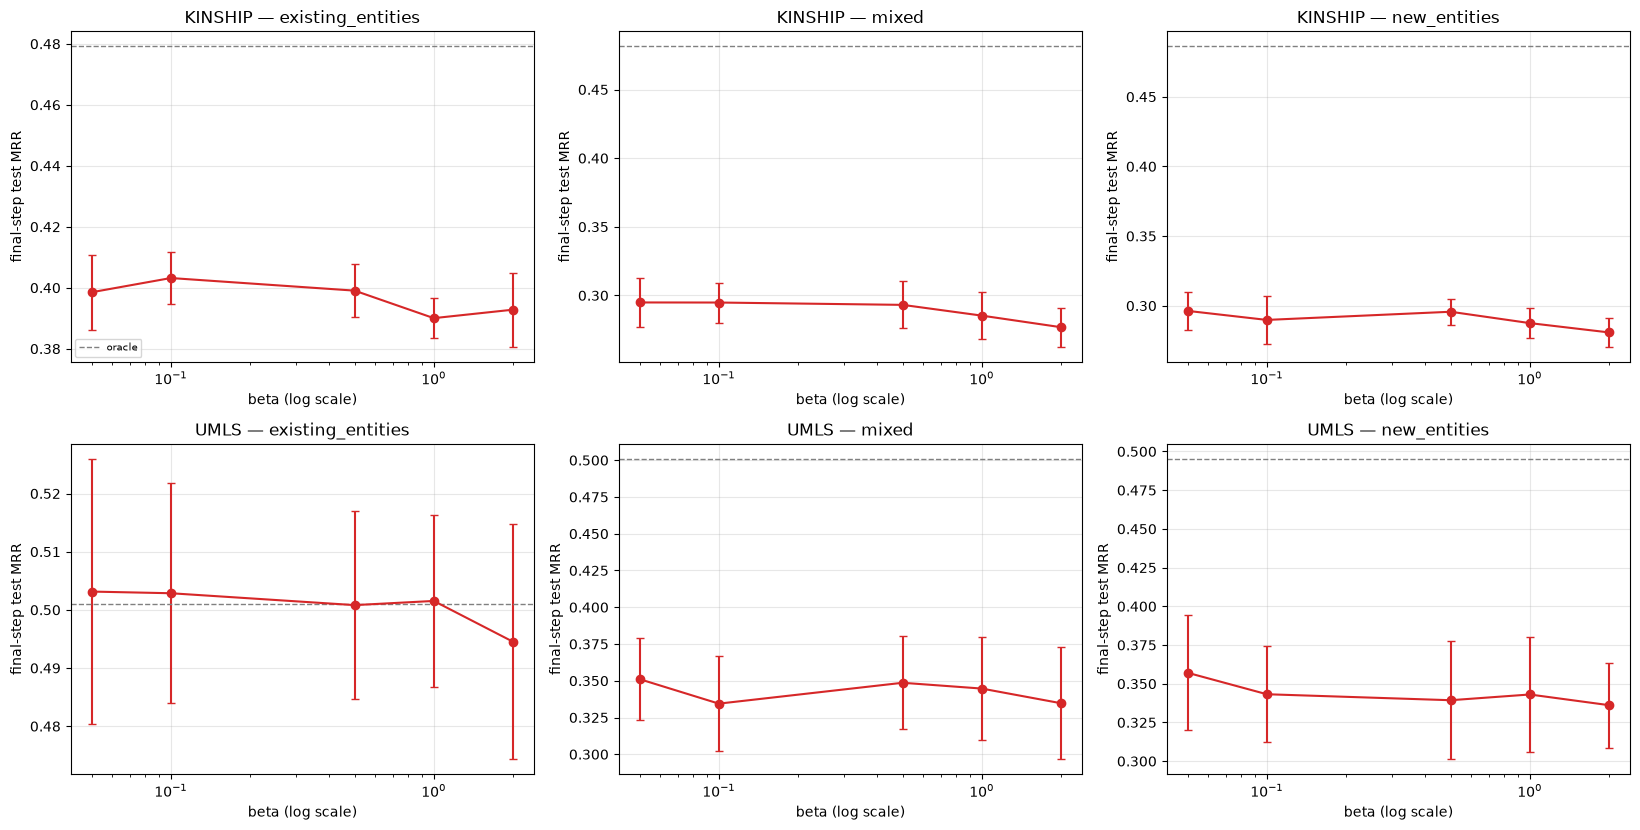

In [62]:
cheb_final = cheb[cheb["step"] == max_step].copy()
cheb_final["beta"] = cheb_final["beta"].astype(float)

fig, axes = plt.subplots(len(datasets), len(scenarios), figsize=(5.5 * len(scenarios), 4.2 * len(datasets)), squeeze=False)

for row, dataset in enumerate(datasets):
    for col, scenario in enumerate(scenarios):
        ax = axes[row][col]
        sub = cheb_final[(cheb_final["dataset"] == dataset) & (cheb_final["scenario"] == scenario)]
        stats = sub.groupby("beta")["test_MRR"].agg(["mean", "std"]).sort_index()
        ax.errorbar(stats.index, stats["mean"], yerr=stats["std"], marker="o", capsize=3, color="tab:red")

        oracle_mean = comparison_df[
            (comparison_df["dataset"] == dataset)
            & (comparison_df["scenario"] == scenario)
            & (comparison_df["method"] == "retrain_from_scratch")
            & (comparison_df["step"] == max_step)
        ]["test_MRR"].mean()
        ax.axhline(oracle_mean, color="gray", linestyle="--", linewidth=1, label="oracle")

        ax.set_xscale("log")
        ax.set_title(f"{dataset} — {scenario}")
        ax.set_xlabel("beta (log scale)")
        ax.set_ylabel("final-step test MRR")
        ax.grid(True, alpha=0.3)
        if row == 0 and col == 0:
            ax.legend(fontsize=7)

plt.tight_layout()
plt.show()


## 9. Chebyshev order (cheb_K) sensitivity analysis

Symmetric to the beta sweep above: for each (dataset, scenario) we fix beta at its previously
selected best value and look at how final-snapshot MRR varies with `cheb_K` (the number of
Chebyshev propagation hops), averaged over seeds. With 5 snapshots, `cheb_K` was swept from 1 to 5
-- this shows whether propagating influence further than a handful of hops actually helps, or
whether it saturates/hurts (e.g. by over-smoothing the influence estimate across the whole graph).


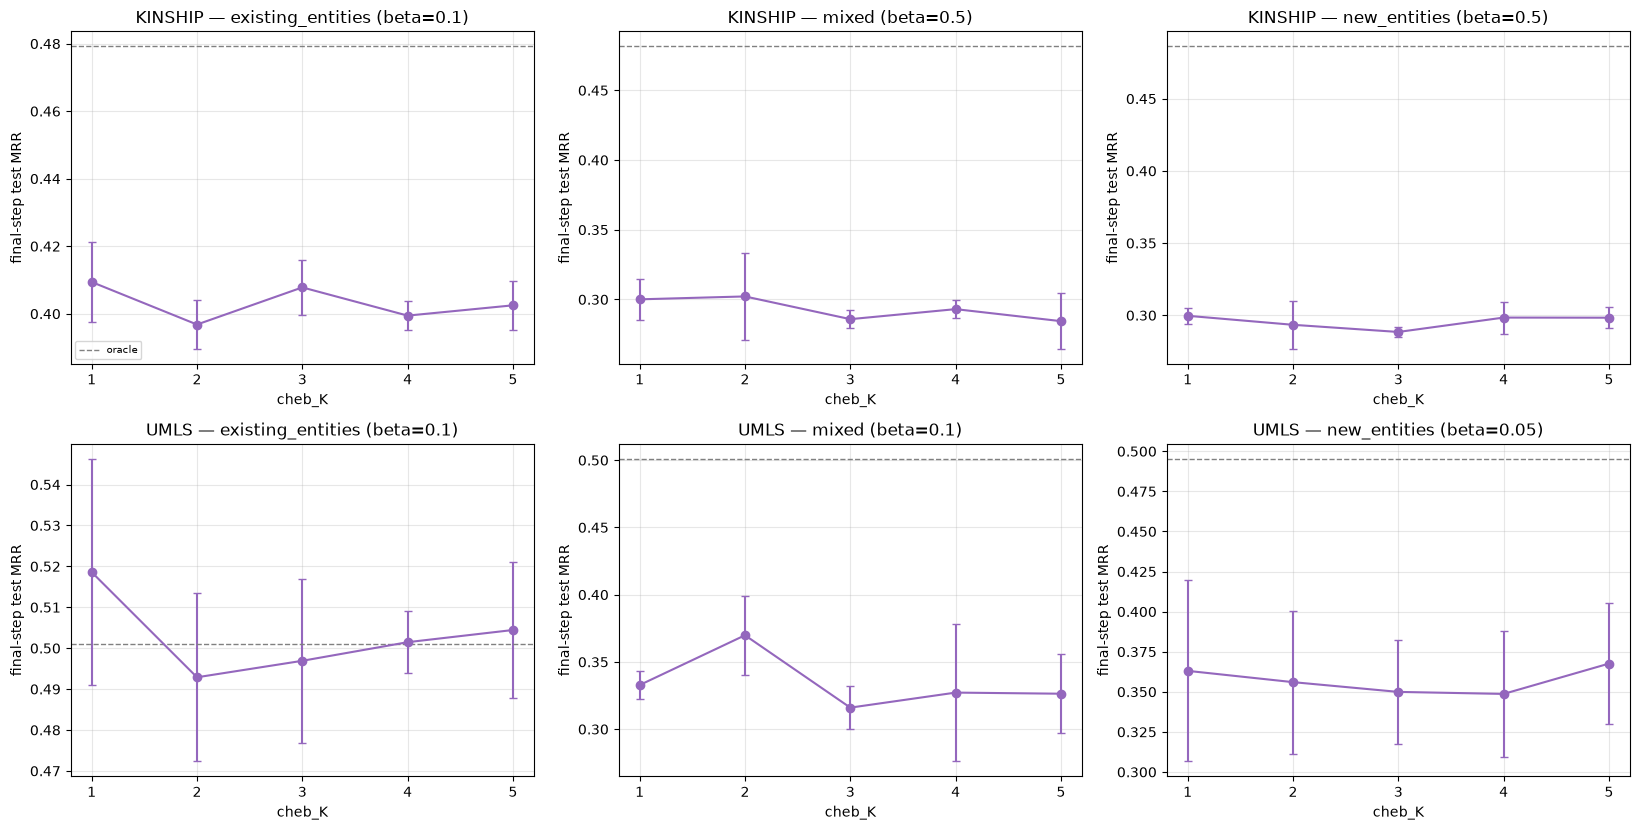

In [63]:
fig, axes = plt.subplots(len(datasets), len(scenarios), figsize=(5.5 * len(scenarios), 4.2 * len(datasets)), squeeze=False)

for row, dataset in enumerate(datasets):
    for col, scenario in enumerate(scenarios):
        ax = axes[row][col]
        best_row = best_configs[(best_configs["dataset"] == dataset) & (best_configs["scenario"] == scenario)]
        if best_row.empty:
            ax.text(0.5, 0.5, "no chebyshev data", ha="center", va="center", transform=ax.transAxes)
            ax.set_title(f"{dataset} — {scenario}")
            continue
        best_beta = float(best_row["best_beta"].iloc[0])

        sub = cheb_final[
            (cheb_final["dataset"] == dataset)
            & (cheb_final["scenario"] == scenario)
            & (cheb_final["beta"] == best_beta)
        ]
        stats = sub.groupby("cheb_K")["test_MRR"].agg(["mean", "std"]).sort_index()
        if not stats.empty:
            ax.errorbar(stats.index, stats["mean"], yerr=stats["std"], marker="o", capsize=3, color="tab:purple")
        else:
            ax.text(0.5, 0.5, "no chebyshev data", ha="center", va="center", transform=ax.transAxes)

        oracle_mean = comparison_df[
            (comparison_df["dataset"] == dataset)
            & (comparison_df["scenario"] == scenario)
            & (comparison_df["method"] == "retrain_from_scratch")
            & (comparison_df["step"] == comparison_df.loc[
                (comparison_df["dataset"] == dataset) & (comparison_df["scenario"] == scenario), "final_step"
            ].iloc[0])
        ]["test_MRR"].mean()
        ax.axhline(oracle_mean, color="gray", linestyle="--", linewidth=1, label="oracle")

        ax.set_title(f"{dataset} — {scenario} (beta={best_beta:g})")
        ax.set_xlabel("cheb_K")
        ax.set_ylabel("final-step test MRR")
        ax.set_xticks(sorted(cheb_final["cheb_K"].dropna().unique()))
        ax.grid(True, alpha=0.3)
        if row == 0 and col == 0:
            ax.legend(fontsize=7)

plt.tight_layout()

plt.show()

## 10. Training loss convergence (summary stats)

The CSV only stores per-run summary loss statistics (`first_epoch_loss`, `last_epoch_loss`,
`min_epoch_loss`, `num_epochs`) rather than full per-epoch curves, so we cannot plot true loss
decay curves here. Instead we visualize the **relative loss reduction**
`(first_epoch_loss - last_epoch_loss) / first_epoch_loss` achieved by each method, and the
average number of epochs used, as a proxy for convergence behavior.


Relative loss reduction and epoch counts per method (mean ± std across scenarios/seeds/steps):


loss_reduction         num_epochs      min_epoch_loss        
                                          mean     std       mean  std           mean     std
dataset method                                                                               
KINSHIP base_model                         NaN     NaN        NaN  NaN            NaN     NaN
        retrain_from_scratch            0.9478  0.0146       50.0  0.0         0.0747  0.0157
        finetune                        0.8742  0.0972       10.0  0.0         0.2632  0.0407
        uniform                         0.8790  0.0947       10.0  0.0         0.2781  0.0332
        chebyshev (best config)         0.8756  0.1007       10.0  0.0         0.2829  0.0353
UMLS    base_model                         NaN     NaN        NaN  NaN            NaN     NaN
        retrain_from_scratch            0.9793  0.0031       50.0  0.0         0.0392  0.0049
        finetune                        0.8833  0.0879       10.0  0.0         0.3421  0.1277
        uniform                         0.8762  0.0897       10.0  0.0         0.3742  0.1143
        chebyshev (best config)         0.8758  0.0887       10.0  0.0         0.3748  0.1058

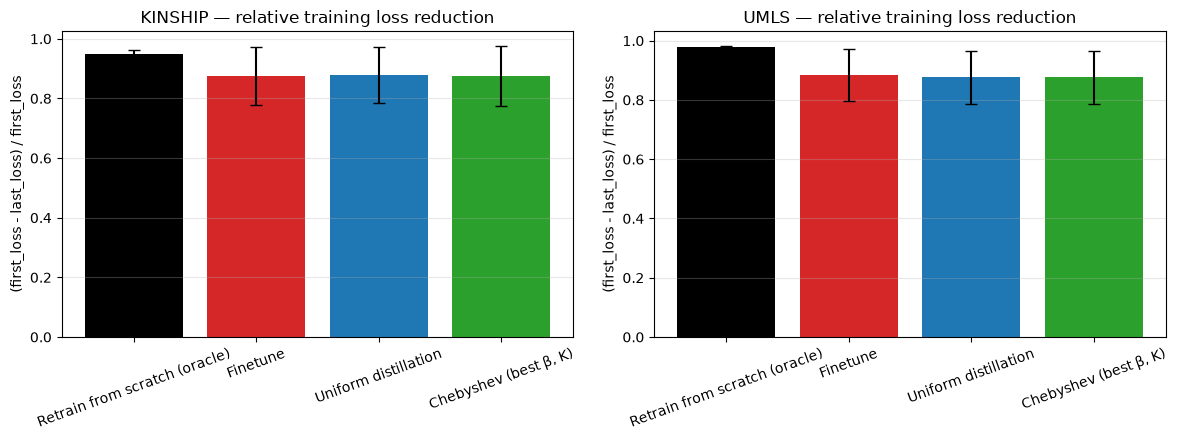

In [64]:
loss_df = comparison_df.copy()
loss_df["loss_reduction"] = (
    (loss_df["first_epoch_loss"] - loss_df["last_epoch_loss"]) / loss_df["first_epoch_loss"]
)

loss_summary = (
    loss_df.groupby(["dataset", "method"])[["loss_reduction", "num_epochs", "min_epoch_loss"]]
    .agg(["mean", "std"])
    .round(4)
)
print("Relative loss reduction and epoch counts per method (mean ± std across scenarios/seeds/steps):")
display(loss_summary)

fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 4.5), squeeze=False)
axes = axes[0]
plot_methods = ["retrain_from_scratch", "finetune", "uniform", "chebyshev (best config)"]

for col, dataset in enumerate(datasets):
    ax = axes[col]
    sub = loss_df[loss_df["dataset"] == dataset]
    means = [sub[sub["method"] == m]["loss_reduction"].mean() for m in plot_methods]
    stds = [sub[sub["method"] == m]["loss_reduction"].std() for m in plot_methods]
    colors = [METHOD_COLORS.get(m, None) for m in plot_methods]
    labels = [METHOD_LABELS.get(m, m) for m in plot_methods]

    ax.bar(labels, means, yerr=stds, capsize=4, color=colors)
    ax.set_title(f"{dataset} — relative training loss reduction")
    ax.set_ylabel("(first_loss - last_loss) / first_loss")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
